# Bank Marketing – Term-Deposit Subscription Prediction


### IT3091 Machine Learning – Guided Data Track (Banking & Finance) | Group 2026-DS-02

## Step 1 – Project Introduction & Problem Framing

### 1. Business Problem
Banks run telephone marketing campaigns to sell term deposits, but calling every
client is costly and many calls end without a sale. By learning from historical
campaign records, a machine learning model can estimate which clients are more
likely to subscribe, so that limited calling capacity is used on the clients
with the best chance of success.

### 2. Stakeholders
The bank's marketing and campaign decision makers, who plan which clients are
contacted and in what order.

### 3. Primary Decision Lens
**Campaign Response Prediction** – estimating whether a client will subscribe
to a term deposit, so that clients can be prioritised before contact.

### 4. Secondary Lens
**Marketing Profile Analysis** – identifying which customer and campaign
characteristics are associated with positive responses. This lens supports the
primary one by explaining who the model ranks highly and why.

### 5. Machine Learning Task
Supervised **binary classification**. The model outputs a subscription
probability, which is used to rank clients for contact.

### 6. Target Variable
The target `y` records whether the client subscribed:
- `yes` → **1** (subscribed to a term deposit)
- `no`  → **0** (did not subscribe)

### 7. Unit of Analysis
One client–campaign contact record (one row). The dataset has no client ID, so
rows belonging to the same client cannot be linked; this is noted as a limitation.

### 8. Leakage Consideration
The variable `duration` (length of the last call) is only known after the call
is finished. Because the intended use is **pre-contact prioritisation**, it is
excluded from the final model. It is used only in a benchmark comparison to show
how much it would inflate performance.

### 9. Expected Output
- A subscription-likelihood score for each client
- A ranked contact list with lift/gain analysis (how many subscribers are
  captured by contacting the top-scoring clients)
- A profile of the clients most likely to respond
- A recommendation for future campaign prioritisation

### 10. Business Value
The model supports **decision-making**, not automatic decisions. By contacting
higher-scoring clients first, the bank can reach more subscribers with fewer
calls. Final decisions remain with the marketing team.


## Step 2 – Project Objective and Dataset

The objective of this project is to develop and compare machine learning models
for predicting whether a bank client will subscribe to a term deposit.

The project will:
1. Explore and understand the Bank Marketing dataset.
2. Identify and handle data-quality issues (duplicates, `unknown` categories, special codes).
3. Prevent data leakage (excluding `duration`, fitting preprocessing only on training data).
4. Engineer suitable features for prediction.
5. Compare a baseline classifier with several machine learning models.
6. Evaluate using metrics suitable for an imbalanced problem (precision, recall,
   F1, ROC-AUC, PR-AUC, lift), not accuracy alone.
7. Select a final model based on predictive performance and interpretability.
8. Identify the characteristics associated with a positive response.
9. Give an evidence-based recommendation, with limitations and responsible-use considerations.

**Dataset:** `bank-additional-full.csv` – 41,188 telephone-campaign records from a
Portuguese bank (May 2008 – November 2010), with 20 input variables and the target `y`.
Source: UCI Machine Learning Repository, *Bank Marketing* (Moro, Cortez & Rita, 2014).

# **Step 1: Setup and load the data**

### 1.1 Libraries and settings

In [78]:
# Standard libraries
import os, hashlib, warnings

# Data handling and plotting
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn tools
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

# Models and evaluation tools
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Imbalance handling and boosting
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# Tuning and tree-based models
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Comparison and statistics
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy import stats

# Threshold analysis tools
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, confusion_matrix

# Calibration tools
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

# Interpretation tools
from sklearn.inspection import permutation_importance

# Display settings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

# Reproducibility
RANDOM_STATE = 42

### 1.2 Dataset fingerprint and loading

In [79]:
# Dataset file name
DATA_FILE = 'bank-additional-full.csv'

# Dataset fingerprint
def sha256_of(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(65536), b''):
            h.update(block)
    return h.hexdigest()

print('SHA-256:', sha256_of(DATA_FILE))

# Load the main dataset
raw = pd.read_csv(DATA_FILE, sep=';')

print('Dataset loaded successfully.')
print('Dataset shape:', raw.shape)

# Preview the first rows
raw.head()

SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8
Dataset loaded successfully.
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1.3 Data Dictionary

| Variable | Type | Meaning | Group |
|---|---|---|---|
| age | numeric | Client age in years | client |
| job | categorical | Job type (12 levels, incl. unknown) | client |
| marital | categorical | Marital status (divorced = divorced or widowed) | client |
| education | categorical | Education level (8 levels, incl. unknown) | client |
| default | categorical | Credit in default? (no / yes / unknown) | client |
| housing | categorical | Has housing loan? | client |
| loan | categorical | Has personal loan? | client |
| contact | categorical | Contact channel (cellular / telephone) | current campaign |
| month | categorical | Month of last contact | current campaign |
| day_of_week | categorical | Weekday of last contact | current campaign |
| duration | numeric | Last call length in seconds; known only after the call (leakage) | current campaign |
| campaign | numeric | Contacts in this campaign for this client, including the last | current campaign |
| pdays | numeric | Days since last contact in a previous campaign (999 = never contacted) | previous campaign |
| previous | numeric | Contacts before this campaign | previous campaign |
| poutcome | categorical | Outcome of the previous campaign | previous campaign |
| emp.var.rate | numeric | Employment variation rate (quarterly) | economic context |
| cons.price.idx | numeric | Consumer price index (monthly) | economic context |
| cons.conf.idx | numeric | Consumer confidence index (monthly) | economic context |
| euribor3m | numeric | 3-month Euribor rate (daily) | economic context |
| nr.employed | numeric | Number of employees (quarterly) | economic context |
| y | binary | Target: subscribed to a term deposit? | target |

**Row meaning:** one contact record of a client in a Portuguese bank's phone campaigns (May 2008 to Nov 2010, in date order). There is no client ID.

# **Step 2: Data-quality checks**

In [80]:
# Duplicates
print('Exact duplicate rows:', raw.duplicated().sum())

# Missing values
print('NaN cells:', int(raw.isna().sum().sum()))

# Hidden missing values
cat_cols = raw.select_dtypes(exclude='number').columns.drop('y')
unk = (raw[cat_cols] == 'unknown').sum()
unk_tbl = pd.DataFrame({'unknown_n': unk,
                        'unknown_%': (unk / len(raw) * 100).round(2)})
display(unk_tbl[unk_tbl.unknown_n > 0].sort_values('unknown_%', ascending=False))

# Check target balance
display(pd.DataFrame({'n': raw.y.value_counts(),
                      'share': raw.y.value_counts(normalize=True).round(4)}))

# Baseline accuracy
print('Always-"no" accuracy:', round((raw.y == 'no').mean(), 4))

# Check special code in pdays
print('pdays == 999 share:', round((raw.pdays == 999).mean(), 3))

Exact duplicate rows: 12
NaN cells: 0


,unknown_n,unknown_%
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


,n,share
y,,
no,36548,0.8873
yes,4640,0.1127


Always-"no" accuracy: 0.8873
pdays == 999 share: 0.963


### Workflow Diagram

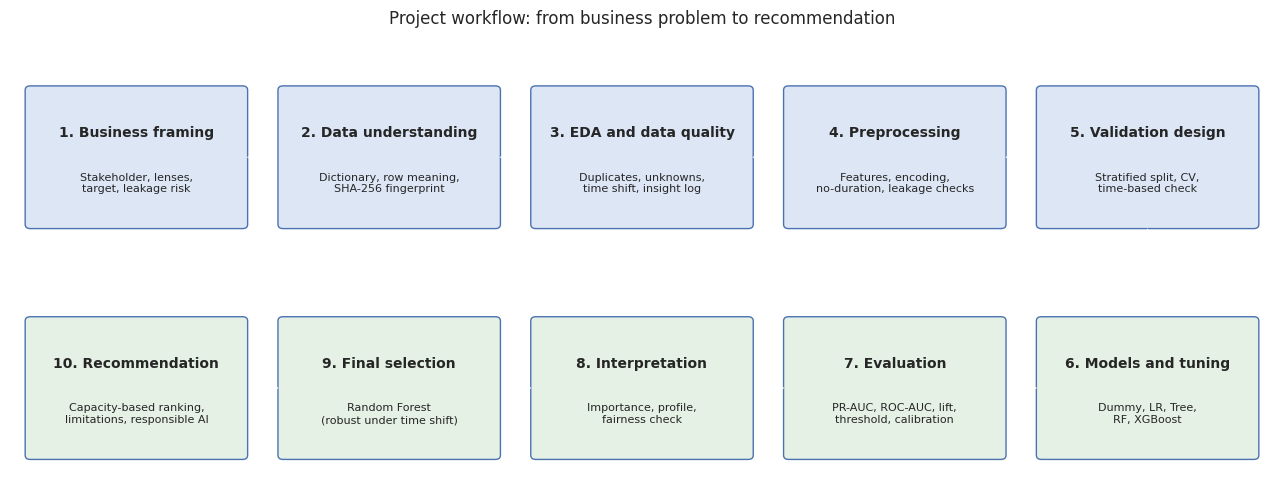

In [81]:
# Workflow diagram
from matplotlib.patches import FancyBboxPatch

steps = [
    ('1. Business framing', 'Stakeholder, lenses,\ntarget, leakage risk'),
    ('2. Data understanding', 'Dictionary, row meaning,\nSHA-256 fingerprint'),
    ('3. EDA and data quality', 'Duplicates, unknowns,\ntime shift, insight log'),
    ('4. Preprocessing', 'Features, encoding,\nno-duration, leakage checks'),
    ('5. Validation design', 'Stratified split, CV,\ntime-based check'),
    ('6. Models and tuning', 'Dummy, LR, Tree,\nRF, XGBoost'),
    ('7. Evaluation', 'PR-AUC, ROC-AUC, lift,\nthreshold, calibration'),
    ('8. Interpretation', 'Importance, profile,\nfairness check'),
    ('9. Final selection', 'Random Forest\n(robust under time shift)'),
    ('10. Recommendation', 'Capacity-based ranking,\nlimitations, responsible AI'),
]
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.set_xlim(0, 5)
ax.set_ylim(0, 2.2)
ax.axis('off')
for i, (title, sub) in enumerate(steps):
    row, col = divmod(i, 5)
    x = col + 0.5 if row == 0 else (4 - col) + 0.5
    y = 1.6 if row == 0 else 0.5
    ax.add_patch(FancyBboxPatch((x - 0.42, y - 0.32), 0.84, 0.64, boxstyle='round,pad=0.02',
                                fc='#DCE6F5' if row == 0 else '#E4F1E4', ec='#4C72B0'))
    ax.text(x, y + 0.12, title, ha='center', va='center', fontsize=10, fontweight='bold')
    ax.text(x, y - 0.12, sub, ha='center', va='center', fontsize=8)
    if i < 9:
        if row == 0 and col < 4:
            ax.annotate('', xy=(x + 0.5, y), xytext=(x + 0.43, y), arrowprops=dict(arrowstyle='->'))
        elif row == 0 and col == 4:
            ax.annotate('', xy=(x, 0.84), xytext=(x, y - 0.33), arrowprops=dict(arrowstyle='->'))
        elif row == 1 and col < 4:
            ax.annotate('', xy=(x - 0.5, y), xytext=(x - 0.43, y), arrowprops=dict(arrowstyle='->'))
ax.set_title('Project workflow: from business problem to recommendation', fontsize=12)
plt.tight_layout()
plt.show()

# **Step 3: Clean copy and target encoding**

In [82]:
# Remove duplicates
df = raw.drop_duplicates().reset_index(drop=True)
print('Rows before:', len(raw), '| after:', len(df), '| removed:', len(raw) - len(df))

# Encode target (yes = 1)
df['y_bin'] = (df['y'] == 'yes').astype(int)

# Target balance after cleaning
print('Positive rate:', round(df['y_bin'].mean(), 4))

# Housing and loan unknown together?
same = ((df['housing'] == 'unknown') & (df['loan'] == 'unknown')).sum()
print('Clients with BOTH housing and loan unknown:', same)

# Default categories
print(df['default'].value_counts())

Rows before: 41188 | after: 41176 | removed: 12
Positive rate: 0.1127
Clients with BOTH housing and loan unknown: 990
default
no         32577
unknown     8596
yes            3
Name: count, dtype: int64


# **Step 4: First EDA look at response rates**

       rows  yes_rate
year                 
2008  27682    0.0484
2009  11436    0.1947
2010   2058    0.5214


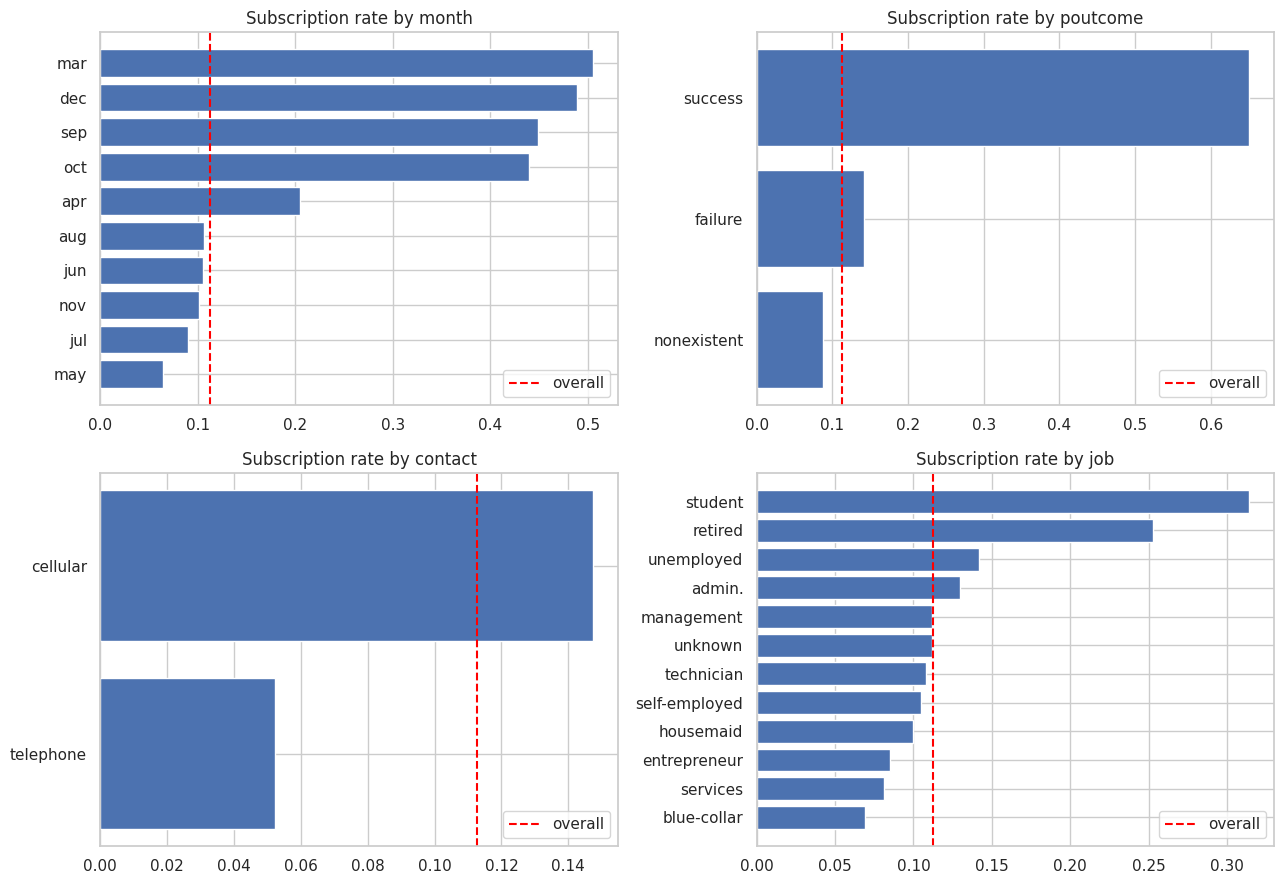

Yes rate, housing unknown: 0.1081
Yes rate, housing known  : 0.1128


In [83]:
# Campaign year
month_num = df['month'].map({'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
                             'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}).values
df['year'] = 2008 + np.cumsum(np.r_[0, (np.diff(month_num) < 0).astype(int)])

# Rate per year
print(df.groupby('year').agg(rows=('y_bin', 'size'), yes_rate=('y_bin', 'mean')).round(4))

# Overall rate
overall = df['y_bin'].mean()

# Rate by category
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, col in zip(ax.ravel(), ['month', 'poutcome', 'contact', 'job']):
    g = df.groupby(col)['y_bin'].mean().sort_values()
    a.barh(g.index, g.values)
    a.axvline(overall, color='red', ls='--', label='overall')
    a.set_title(f'Subscription rate by {col}')
    a.legend()
plt.tight_layout()
plt.show()

# Housing unknown vs known
blank = (df['housing'] == 'unknown')
print('Yes rate, housing unknown:', round(df.loc[blank, 'y_bin'].mean(), 4))
print('Yes rate, housing known  :', round(df.loc[~blank, 'y_bin'].mean(), 4))

# **Step 5: Numeric variables and leakage evidence**

           size   mean
age_band              
<25        1067  0.240
25-34     13684  0.122
35-44     13495  0.087
45-54      8702  0.086
55-64      3566  0.136
65+         662  0.473


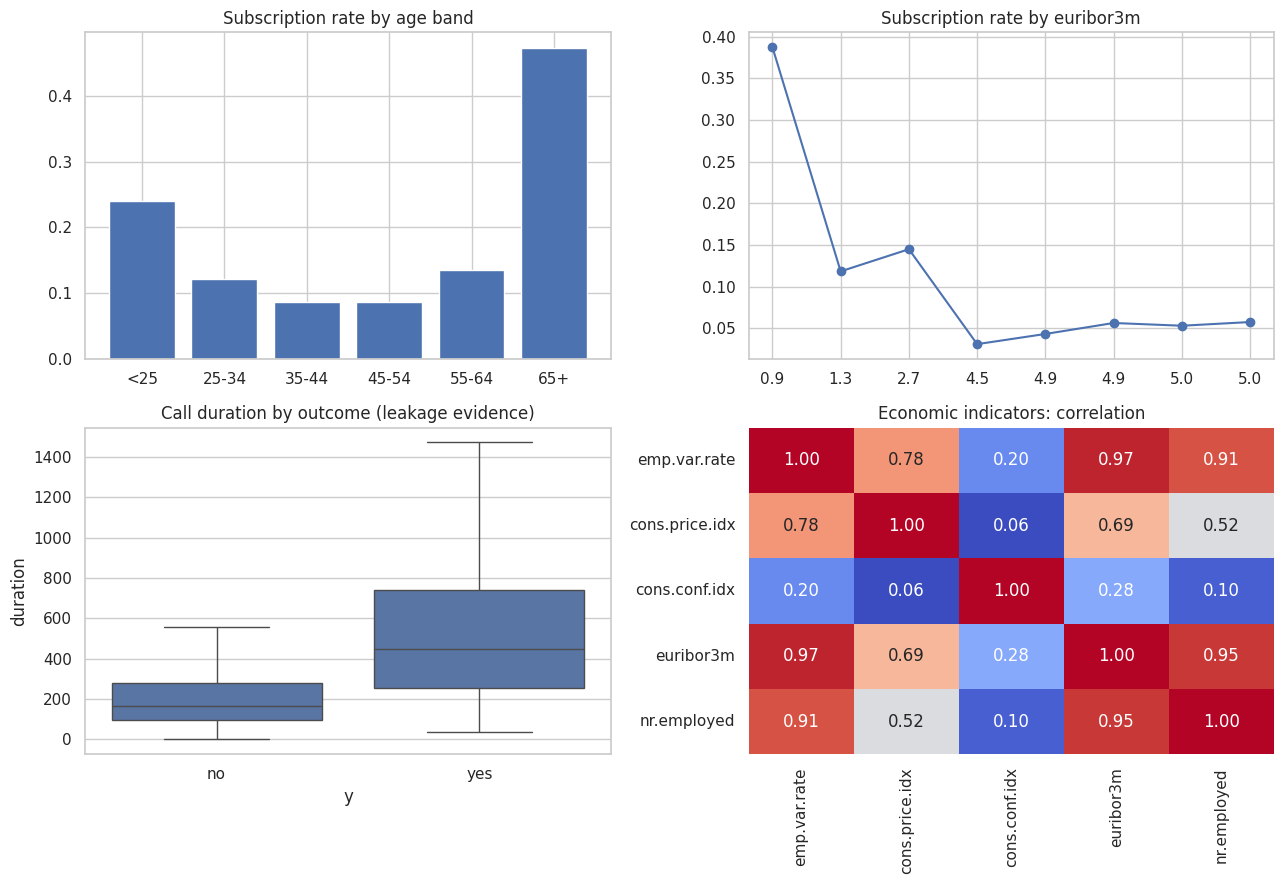

y
no     164.0
yes    449.0
Name: duration, dtype: float64


In [84]:
# Group age into bands to see the response pattern
df['age_band'] = pd.cut(df['age'], [0, 24, 34, 44, 54, 64, 120],
                        labels=['<25', '25-34', '35-44', '45-54', '55-64', '65+'])
print(df.groupby('age_band', observed=False)['y_bin'].agg(['size', 'mean']).round(3))

# Euribor bins
df['euribor_bin'] = pd.qcut(df['euribor3m'], 8, duplicates='drop')

# Plots
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

g = df.groupby('age_band', observed=False)['y_bin'].mean()
ax[0, 0].bar(g.index.astype(str), g.values)
ax[0, 0].set_title('Subscription rate by age band')

g = df.groupby('euribor_bin', observed=False)['y_bin'].mean()
ax[0, 1].plot(range(len(g)), g.values, marker='o')
ax[0, 1].set_xticks(range(len(g)))
ax[0, 1].set_xticklabels([f'{i.mid:.1f}' for i in g.index])
ax[0, 1].set_title('Subscription rate by euribor3m')

sns.boxplot(data=df, x='y', y='duration', showfliers=False, ax=ax[1, 0])
ax[1, 0].set_title('Call duration by outcome (leakage evidence)')

econ = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
sns.heatmap(df[econ].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1, 1], cbar=False)
ax[1, 1].set_title('Economic indicators: correlation')

plt.tight_layout()
plt.show()

# Compare the typical call length for yes vs no
print(df.groupby('y')['duration'].median())

## EDA Insight Log

| # | Area | Finding | Implication for ML |
|---|---|---|---|
| 1 | Target | 88.73% no / 11.27% yes | Imbalanced: stratified split, PR-AUC, recall/precision; accuracy misleading (baseline 0.8873) |
| 2 | Duplicates | 12 exact duplicate rows | Remove before splitting |
| 3 | Missing values | 0 NaN, but "unknown" in 6 columns (default 20.87%, education 4.20%, housing/loan 2.40%, job 0.80%, marital 0.19%) | Missing data hidden as text; needs explicit handling |
| 4 | pdays | 96.3% are 999 (never contacted) | Special code; convert to flag + cleaned value |
| 5 | housing / loan | Same 990 rows unknown for both | Block-missing; keeping "unknown" preserves it |
| 6 | default | no 32,577 / unknown 8,596 / yes only 3 | "yes" too rare; group rare levels |
| 7 | Time | Yes rate 2008: 4.8% (27,682 rows), 2009: 19.5% (11,436), 2010: 52.1% (2,058); last 20% of rows 30.8% vs 6.4% | Strong shift; random split main, time split as sensitivity check |
| 8 | month | mar 50.5%, dec 48.9%, sep 44.9%, oct 43.9% (small, mostly 2009-2010); may 6.4% on 13,767 rows | Month is confounded with year |
| 9 | poutcome | success about 65% overall (57% in 2009, 77% in 2010) | Strongest, most stable predictor |
| 10 | contact | cellular > telephone in every year | Real effect; telephone concentrated in 2008 |
| 11 | housing unknown | 10.8% vs 11.3% yes | No meaningful signal by itself |
| 12 | age | <25 24.0%, 35-54 about 8.6%, 65+ 47.3% (662 rows) | U-shaped: add bands; 65+ noisy |
| 13 | euribor3m | About 39% yes in the lowest bin, 3-6% above 4.5 | Strong but tied to time period |
| 14 | Economic indicators | euribor3m correlates 0.97 with emp.var.rate, 0.95 with nr.employed | Multicollinearity: affects LR coefficients, not trees |
| 15 | duration | Median 449 s (yes) vs 164 s (no) | Strong but unknown before the call: leakage |

# **Step 6: Features and the train/test split**

In [85]:
# Feature engineering
df['prev_contacted'] = (df['pdays'] != 999).astype(int)
df['pdays_clean'] = df['pdays'].where(df['pdays'] != 999, 0)
df['age_band'] = df['age_band'].astype(str)

# Feature groups
cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                'contact', 'month', 'day_of_week', 'poutcome', 'age_band']
num_features = ['age', 'campaign', 'previous', 'prev_contacted', 'pdays_clean',
                'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
feature_cols = cat_features + num_features

# Inputs and target
X = df[feature_cols].copy()
y = df['y_bin'].copy()
duration_all = df['duration'].copy()

# Train/test split
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Yes rate - train:', round(y_train.mean(), 4), '| test:', round(y_test.mean(), 4))

# Leakage checks
assert 'duration' not in X.columns, 'duration leaked into features'
assert not {'y', 'y_bin', 'year'} & set(X.columns), 'target or year leaked into features'
assert len(set(train_idx) & set(test_idx)) == 0, 'train and test overlap'
print('Leakage checks passed.')

Train: (32940, 21) | Test: (8236, 21)
Yes rate - train: 0.1127 | test: 0.1127
Leakage checks passed.


# **Step 7: Preprocessing pipeline**

In [86]:
# Feature groups
skewed = ['campaign', 'previous']
plain_num = [c for c in num_features if c not in skewed]

# Preprocessor
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist',
                          min_frequency=30, sparse_output=False), cat_features),
    ('skew', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                       ('scale', StandardScaler())]), skewed),
    ('num', StandardScaler(), plain_num),
])

# Fit on train only
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print('Before encoding:', X_train.shape, '| After encoding:', X_train_p.shape)
print('Train feature means (about 0):', np.round(X_train_p[:, -10:].mean(axis=0), 3))
print('Test feature means (close to 0, not exact):', np.round(X_test_p[:, -10:].mean(axis=0), 3))

# Grouped categories
names = preprocessor.get_feature_names_out()
print('Grouped rare categories:', [n for n in names if 'infrequent' in n])

Before encoding: (32940, 21) | After encoding: (32940, 69)
Train feature means (about 0): [ 0.  0. -0.  0. -0.  0.  0. -0. -0. -0.]
Test feature means (close to 0, not exact): [ 0.012 -0.005  0.003  0.004 -0.006  0.006  0.001  0.008  0.009  0.009]
Grouped rare categories: ['cat__education_infrequent_sklearn', 'cat__default_infrequent_sklearn']


## Preprocessing and Feature Log

| # | Issue / Feature | Action | Reason | Where |
|---|---|---|---|---|
| 1 | 12 exact duplicate rows | Removed before splitting (kept first, original date order) | Copies in train and test would inflate scores | Step 3 |
| 2 | "unknown" categories (default 20.87%, education 4.20%, housing/loan 2.40%, job 0.80%, marital 0.19%) | Kept as their own category level | Dropping would lose up to 21% of rows; imputing would invent values; unknown may carry information | Step 7 |
| 3 | pdays = 999 (96.3%) | Created `prev_contacted` flag and `pdays_clean` (999 replaced by 0) | 999 is a code for "never contacted", not a number of days | Step 6 |
| 4 | age (U-shaped response) | Kept numeric and added `age_band` | A linear term cannot capture the U-shape | Step 6 |
| 5 | Rare categories (e.g. default = yes, 3 rows) | Grouped as "infrequent" when under 30 rows | Too rare to learn from reliably | Step 7 |
| 6 | Categorical encoding | One-hot encoding (21 features became 69 columns) | No natural order in the categories | Step 7 |
| 7 | Skewed counts (campaign, previous) | log(1 + x) then standardise | Long right tails | Step 7 |
| 8 | Numeric scaling | StandardScaler on other numerics | Needed for logistic regression; harmless for trees | Step 7 |
| 9 | Class imbalance (11.27% yes) | Class weights; SMOTE and no handling compared | Equal ranking quality, simpler, no synthetic data | Step 9 |
| 10 | Leakage: `duration` | Excluded from all models; used only in an ablation | Unknown before the call | Steps 6, 15 |
| 11 | Leakage: year, target | Excluded by explicit feature list and assertions | Year is for EDA and time-split only | Step 6 |
| 12 | Collinear economic indicators (correlation up to 0.97) | Kept, tested in an ablation | Trees tolerate collinearity; value measured | Steps 5, 15 |
| 13 | Fitting preprocessing | Inside a Pipeline, re-fitted per training fold | Prevents leakage into validation folds | Steps 7, 8 |

# **Step 8: Evaluation framework and baselines**

In [87]:
# Cross-validation setup and metrics
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
}

# Reusable cross-validation report
def cv_report(name, model):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    return pd.Series({m: f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}"
                      for m in scoring}, name=name)

# Baseline models
models = {
    'Dummy (always no)': Pipeline([('prep', preprocessor),
                                   ('clf', DummyClassifier(strategy='prior'))]),
    'Logistic Regression (balanced)': Pipeline([('prep', preprocessor),
                                   ('clf', LogisticRegression(class_weight='balanced',
                                                              max_iter=1000,
                                                              random_state=RANDOM_STATE))]),
}

# Compare baselines
baseline_results = pd.DataFrame([cv_report(n, m) for n, m in models.items()])
baseline_results

,accuracy,precision,recall,f1,roc_auc,pr_auc
Dummy (always no),0.887 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.113 ± 0.000
Logistic Regression (balanced),0.830 ± 0.004,0.355 ± 0.007,0.625 ± 0.012,0.452 ± 0.008,0.790 ± 0.007,0.445 ± 0.013


# **Step 9: Handling Class Imbalance**

In [88]:
# Class weight for XGBoost
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Model builders
def lr(**kw):
    return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **kw)

def xgb(**kw):
    return XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.8, eval_metric='logloss',
                         random_state=RANDOM_STATE, n_jobs=1, **kw)

# Imbalance strategies
imbalance_models = {
    'LR - no handling': Pipeline([('prep', preprocessor), ('clf', lr())]),
    'LR - class weight': Pipeline([('prep', preprocessor), ('clf', lr(class_weight='balanced'))]),
    'LR - SMOTE': ImbPipeline([('prep', preprocessor), ('smote', SMOTE(random_state=RANDOM_STATE)),
                               ('clf', lr())]),
    'XGB - no handling': Pipeline([('prep', preprocessor), ('clf', xgb())]),
    'XGB - class weight': Pipeline([('prep', preprocessor), ('clf', xgb(scale_pos_weight=pos_weight))]),
    'XGB - SMOTE': ImbPipeline([('prep', preprocessor), ('smote', SMOTE(random_state=RANDOM_STATE)),
                                ('clf', xgb())]),
}

# Compare strategies
imbalance_results = pd.DataFrame([cv_report(n, m) for n, m in imbalance_models.items()])
print('Class weight for XGBoost:', round(pos_weight, 2))
imbalance_results

Class weight for XGBoost: 7.88


,accuracy,precision,recall,f1,roc_auc,pr_auc
LR - no handling,0.900 ± 0.002,0.666 ± 0.030,0.234 ± 0.003,0.347 ± 0.006,0.789 ± 0.007,0.450 ± 0.013
LR - class weight,0.830 ± 0.004,0.355 ± 0.007,0.625 ± 0.012,0.452 ± 0.008,0.790 ± 0.007,0.445 ± 0.013
LR - SMOTE,0.823 ± 0.004,0.343 ± 0.008,0.622 ± 0.016,0.442 ± 0.010,0.786 ± 0.008,0.441 ± 0.016
XGB - no handling,0.901 ± 0.001,0.656 ± 0.022,0.255 ± 0.006,0.367 ± 0.006,0.801 ± 0.009,0.469 ± 0.015
XGB - class weight,0.836 ± 0.004,0.367 ± 0.009,0.629 ± 0.012,0.463 ± 0.009,0.800 ± 0.008,0.466 ± 0.013
XGB - SMOTE,0.892 ± 0.003,0.525 ± 0.020,0.396 ± 0.009,0.452 ± 0.013,0.789 ± 0.012,0.447 ± 0.016


# **Step 10: Hyperparameter Tuning**

In [89]:
# Tuning setup
tune_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(clf):
    return Pipeline([('prep', preprocessor), ('clf', clf)])

# Search spaces
searches = {
    'Logistic Regression': GridSearchCV(
        make_pipe(LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)),
        {'clf__C': [0.01, 0.1, 1, 10]},
        scoring='average_precision', cv=tune_cv, n_jobs=-1),
    'Decision Tree': GridSearchCV(
        make_pipe(DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
        {'clf__max_depth': [3, 4, 5, 6, 8], 'clf__min_samples_leaf': [20, 50, 100, 200]},
        scoring='average_precision', cv=tune_cv, n_jobs=-1),
    'Random Forest': RandomizedSearchCV(
        make_pipe(RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample',
                                         random_state=RANDOM_STATE, n_jobs=1)),
        {'clf__max_depth': [6, 10, 14], 'clf__min_samples_leaf': [5, 20, 50],
         'clf__max_features': ['sqrt', 0.3]},
        n_iter=6, scoring='average_precision', cv=tune_cv, n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost': RandomizedSearchCV(
        make_pipe(XGBClassifier(eval_metric='logloss', scale_pos_weight=pos_weight,
                                random_state=RANDOM_STATE, n_jobs=1)),
        {'clf__n_estimators': [150, 300, 500], 'clf__max_depth': [3, 4, 5, 6],
         'clf__learning_rate': [0.03, 0.05, 0.1], 'clf__min_child_weight': [1, 5, 10],
         'clf__subsample': [0.7, 0.9], 'clf__colsample_bytree': [0.6, 0.8, 1.0]},
        n_iter=10, scoring='average_precision', cv=tune_cv, n_jobs=-1, random_state=RANDOM_STATE),
}

# Run the searches
best_models = {}
tuning_rows = []
for name, search in searches.items():
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    tuning_rows.append({'Model': name,
                        'Best CV PR-AUC': round(search.best_score_, 3),
                        'Best parameters': {k.replace('clf__', ''): v for k, v in search.best_params_.items()}})

# Show tuning results
pd.set_option('display.max_colwidth', 200)
pd.DataFrame(tuning_rows)

,Model,Best CV PR-AUC,Best parameters
0,Logistic Regression,0.444,{'C': 1}
1,Decision Tree,0.428,"{'max_depth': 8, 'min_samples_leaf': 50}"
2,Random Forest,0.464,"{'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 14}"
3,XGBoost,0.463,"{'subsample': 0.7, 'n_estimators': 500, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 1.0}"


# **Step 11: Model Comparison**

### 11.1 Repeated Cross-Validation Comparison of Tuned Models

In [90]:
# Capture rate in the top 20% of scored clients
def capture_at(y_true, p, frac=0.2):
    y_arr = np.asarray(y_true)
    k = int(np.ceil(frac * len(y_arr)))
    top = np.argsort(-p)[:k]
    return y_arr[top].sum() / y_arr.sum()

# Models to compare (tuned models from Step 10)
compare_models = {'Dummy (always no)': make_pipe(DummyClassifier(strategy='prior')), **best_models}

# Repeated stratified cross-validation (5 folds x 2 repeats)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)

# Fit each model on every fold and record the scores
rows = []
for name, model in compare_models.items():
    for fold, (tr_i, va_i) in enumerate(rcv.split(X_train, y_train)):
        m = clone(model).fit(X_train.iloc[tr_i], y_train.iloc[tr_i])
        p = m.predict_proba(X_train.iloc[va_i])[:, 1]
        yv = y_train.iloc[va_i]
        pred = (p >= 0.5).astype(int)
        rows.append({'model': name, 'fold': fold,
                     'roc_auc': roc_auc_score(yv, p),
                     'pr_auc': average_precision_score(yv, p),
                     'precision': precision_score(yv, pred, zero_division=0),
                     'recall': recall_score(yv, pred, zero_division=0),
                     'f1': f1_score(yv, pred, zero_division=0),
                     'capture_top20': capture_at(yv, p, 0.2)})
fold_scores = pd.DataFrame(rows)

# Summary table: mean ± std over 10 folds
metrics = ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'capture_top20']
summary = fold_scores.groupby('model', sort=False)[metrics].agg(['mean', 'std'])
comparison_table = pd.DataFrame({m: summary[m]['mean'].round(3).astype(str) + ' ± ' +
                                    summary[m]['std'].round(3).astype(str) for m in metrics})
comparison_table

,roc_auc,pr_auc,precision,recall,f1,capture_top20
model,,,,,,
Dummy (always no),0.5 ± 0.0,0.113 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.189 ± 0.009
Logistic Regression,0.79 ± 0.007,0.446 ± 0.011,0.354 ± 0.007,0.625 ± 0.018,0.452 ± 0.01,0.626 ± 0.016
Decision Tree,0.781 ± 0.01,0.428 ± 0.016,0.34 ± 0.017,0.632 ± 0.024,0.442 ± 0.014,0.624 ± 0.018
Random Forest,0.798 ± 0.009,0.465 ± 0.015,0.396 ± 0.009,0.611 ± 0.013,0.48 ± 0.01,0.636 ± 0.013
XGBoost,0.8 ± 0.008,0.465 ± 0.012,0.363 ± 0.008,0.637 ± 0.016,0.463 ± 0.01,0.639 ± 0.015


### 11.2 Significance Test and PR-AUC Distribution

Best model by mean PR-AUC: XGBoost


,Compared with,Mean PR-AUC difference,t,p-value
0,Decision Tree,0.0371,6.29,0.0001
1,Dummy (always no),0.3527,49.48,0.0000
2,Logistic Regression,0.0196,3.72,0.0048
3,Random Forest,0.0007,0.20,0.8467


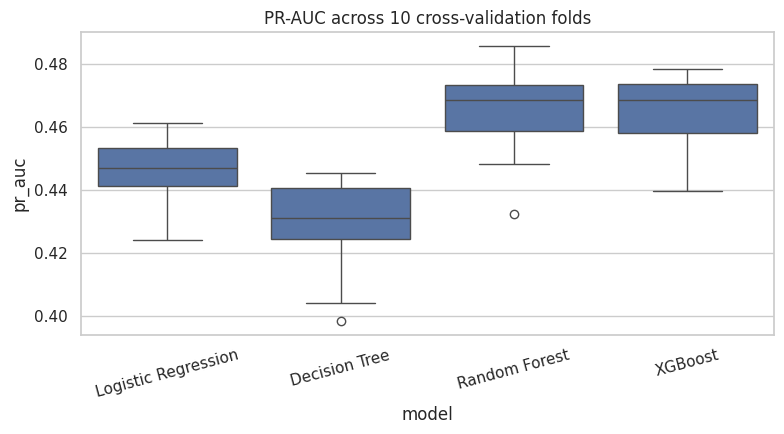

In [91]:
# Best model by mean PR-AUC
best_name = fold_scores.groupby('model')['pr_auc'].mean().idxmax()
print('Best model by mean PR-AUC:', best_name)

# Corrected resampled paired t-test against the best model
pr = fold_scores.pivot(index='fold', columns='model', values='pr_auc')
k = len(pr)
test_ratio = 1 / 4
results = []
for m in pr.columns:
    if m == best_name:
        continue
    d = pr[best_name] - pr[m]
    t = d.mean() / np.sqrt((1 / k + test_ratio) * d.var(ddof=1))
    p_value = 2 * stats.t.sf(abs(t), k - 1)
    results.append({'Compared with': m, 'Mean PR-AUC difference': round(d.mean(), 4),
                    't': round(t, 2), 'p-value': round(p_value, 4)})
display(pd.DataFrame(results))

# PR-AUC per fold for each model
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=fold_scores[fold_scores['model'] != 'Dummy (always no)'], x='model', y='pr_auc')
plt.title('PR-AUC across 10 cross-validation folds')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# **Step 12: Threshold Analysis**

### 12.1 Out-of-Fold Scores and Threshold Table

In [92]:
# Final scoring model
final_name = 'Random Forest'
final_model = best_models[final_name]

# Out-of-fold probabilities on the training set
oof_proba = cross_val_predict(clone(final_model), X_train, y_train, cv=cv,
                              method='predict_proba', n_jobs=1)[:, 1]

# Precision, recall and F1 at every threshold
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_i = f1_curve.argmax()
best_threshold = thr[best_i]

# Summary at selected thresholds
rows = []
for t in [0.3, 0.4, 0.5, 0.6, round(best_threshold, 3)]:
    pred = oof_proba >= t
    rows.append({'Threshold': t,
                 'Clients flagged': round(pred.mean(), 3),
                 'Precision': round(precision_score(y_train, pred), 3),
                 'Recall': round(recall_score(y_train, pred), 3),
                 'F1': round(f1_score(y_train, pred), 3)})
threshold_table = pd.DataFrame(rows)
print('F1-maximising threshold:', round(best_threshold, 3))
threshold_table

F1-maximising threshold: 0.632


,Threshold,Clients flagged,Precision,Recall,F1
0,0.300,0.474,0.191,0.805,0.309
1,0.400,0.243,0.310,0.669,0.424
2,0.500,0.174,0.395,0.611,0.480
3,0.600,0.151,0.435,0.583,0.499
4,0.632,0.146,0.443,0.576,0.501


### 12.2 Precision-Recall Trade-off Plot

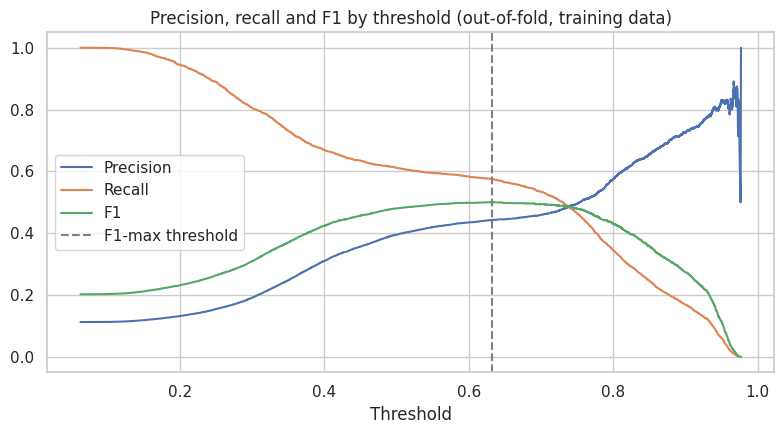

In [93]:
# Precision and recall against the threshold
plt.figure(figsize=(8, 4.5))
plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.plot(thr, f1_curve, label='F1')
plt.axvline(best_threshold, color='gray', ls='--', label='F1-max threshold')
plt.xlabel('Threshold')
plt.title('Precision, recall and F1 by threshold (out-of-fold, training data)')
plt.legend()
plt.tight_layout()
plt.show()

# **Step 13: Final Evaluation on the Test Set**

### 13.1 Test-Set Performance of All Models

In [94]:
# Fit every model on the full training set and score the test set
test_rows = []
test_proba = {}
for name, model in compare_models.items():
    m = clone(model).fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    test_proba[name] = p
    pred = (p >= 0.5).astype(int)
    test_rows.append({'Model': name,
                      'ROC-AUC': roc_auc_score(y_test, p),
                      'PR-AUC': average_precision_score(y_test, p),
                      'Precision@0.5': precision_score(y_test, pred, zero_division=0),
                      'Recall@0.5': recall_score(y_test, pred, zero_division=0),
                      'F1@0.5': f1_score(y_test, pred, zero_division=0),
                      'Capture top 20%': capture_at(y_test, p, 0.2)})

# Test-set results
test_results = pd.DataFrame(test_rows).round(3)
test_results

,Model,ROC-AUC,PR-AUC,Precision@0.5,Recall@0.5,F1@0.5,Capture top 20%
0,Dummy (always no),0.500,0.113,0.000,0.000,0.000,0.197
1,Logistic Regression,0.801,0.448,0.363,0.650,0.466,0.649
2,Decision Tree,0.801,0.462,0.357,0.664,0.465,0.657
3,Random Forest,0.813,0.486,0.409,0.638,0.498,0.661
4,XGBoost,0.813,0.480,0.381,0.666,0.485,0.668


### 13.2 Operating Point, Confusion Matrix and Confidence Intervals

In [95]:
# Apply the threshold chosen on training data to the final model
p_final = test_proba[final_name]
pred_final = (p_final >= best_threshold).astype(int)
print('Threshold:', round(best_threshold, 3))
print('Clients flagged:', round(pred_final.mean(), 3))
print('Precision:', round(precision_score(y_test, pred_final), 3))
print('Recall:', round(recall_score(y_test, pred_final), 3))
print('F1:', round(f1_score(y_test, pred_final), 3))

# Confusion matrix
cm = confusion_matrix(y_test, pred_final)
display(pd.DataFrame(cm, index=['Actual no', 'Actual yes'], columns=['Predicted no', 'Predicted yes']))

# Bootstrap 95% confidence intervals (1000 resamples of the test set)
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.values
boot = []
for _ in range(1000):
    ix = rng.integers(0, len(y_arr), len(y_arr))
    boot.append((roc_auc_score(y_arr[ix], p_final[ix]),
                 average_precision_score(y_arr[ix], p_final[ix]),
                 capture_at(y_arr[ix], p_final[ix], 0.2)))
ci = np.percentile(np.array(boot), [2.5, 97.5], axis=0)
pd.DataFrame(ci.round(3), index=['2.5%', '97.5%'], columns=['ROC-AUC', 'PR-AUC', 'Capture top 20%'])

Threshold: 0.632
Clients flagged: 0.147
Precision: 0.465
Recall: 0.607
F1: 0.526


,Predicted no,Predicted yes
Actual no,6659,649
Actual yes,365,563


,ROC-AUC,PR-AUC,Capture top 20%
2.5%,0.797,0.451,0.634
97.5%,0.830,0.521,0.690


# **Step 14: Lift, Gain and Business Value**

###14.1 Lift Table by Decile

In [96]:
# Overall subscription rate in the test set
base_rate = y_test.mean()

# Lift table (decile 1 = highest scored 10% of clients)
def decile_table(y_true, p):
    d = pd.DataFrame({'y': np.asarray(y_true), 'p': p}).sort_values('p', ascending=False).reset_index(drop=True)
    d['Decile'] = (np.arange(len(d)) * 10 // len(d)) + 1
    t = d.groupby('Decile').agg(Clients=('y', 'size'), Subscribers=('y', 'sum'))
    t['Yes rate'] = t['Subscribers'] / t['Clients']
    t['Lift'] = t['Yes rate'] / base_rate
    t['Cum. subscribers captured'] = t['Subscribers'].cumsum() / t['Subscribers'].sum()
    t['Cum. lift'] = t['Cum. subscribers captured'] / (t.index / 10)
    return t

lift_table = decile_table(y_test, test_proba[final_name])
lift_table.round(3)

,Clients,Subscribers,Yes rate,Lift,Cum. subscribers captured,Cum. lift
Decile,,,,,,
1,824,429,0.521,4.621,0.462,4.623
2,824,184,0.223,1.982,0.661,3.303
3,823,74,0.090,0.798,0.740,2.468
4,824,53,0.064,0.571,0.797,1.994
5,823,41,0.050,0.442,0.842,1.683
6,824,32,0.039,0.345,0.876,1.460
7,824,39,0.047,0.420,0.918,1.312
8,823,22,0.027,0.237,0.942,1.177
9,824,25,0.030,0.269,0.969,1.076


### 14.2 Gain Curves and Lift Chart

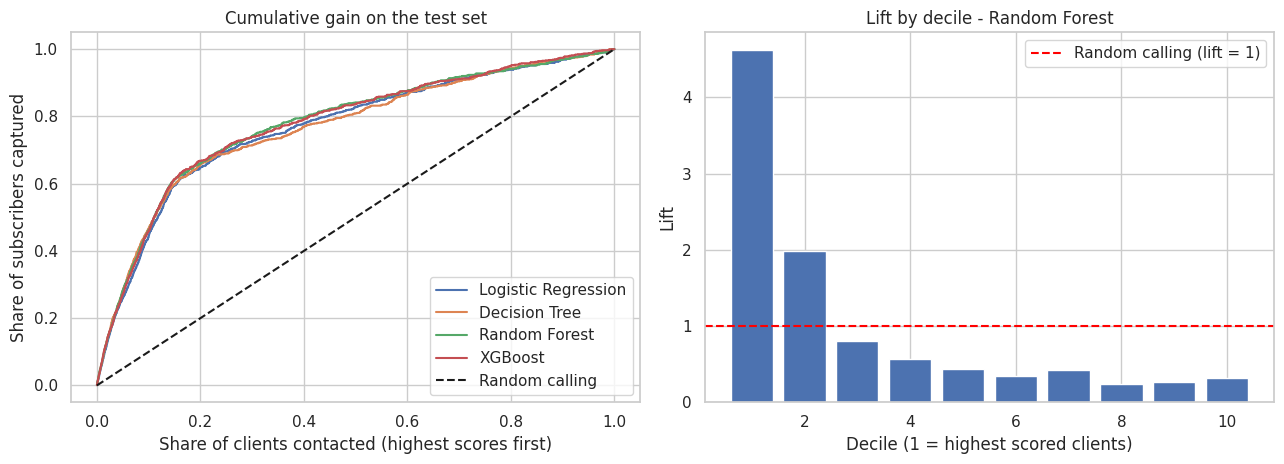

In [97]:
# Cumulative gain: share of subscribers found vs share of clients contacted
def gain_curve(y_true, p):
    order = np.argsort(-p)
    y_sorted = np.asarray(y_true)[order]
    x = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
    return x, np.cumsum(y_sorted) / y_sorted.sum()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

# Gain curves for all models
for name, p in test_proba.items():
    if name == 'Dummy (always no)':
        continue
    x, g = gain_curve(y_test, p)
    ax[0].plot(x, g, label=name)
ax[0].plot([0, 1], [0, 1], 'k--', label='Random calling')
ax[0].set_xlabel('Share of clients contacted (highest scores first)')
ax[0].set_ylabel('Share of subscribers captured')
ax[0].set_title('Cumulative gain on the test set')
ax[0].legend()

# Lift by decile for the final model
ax[1].bar(lift_table.index, lift_table['Lift'], color='#4C72B0')
ax[1].axhline(1, color='red', ls='--', label='Random calling (lift = 1)')
ax[1].set_xlabel('Decile (1 = highest scored clients)')
ax[1].set_ylabel('Lift')
ax[1].set_title(f'Lift by decile - {final_name}')
ax[1].legend()
plt.tight_layout()
plt.show()

### 14.3 Cost-Benefit View

In [98]:
# Net gain in units of "one contact cost", for how many deciles to call
cost_rows = []
for value in [5, 10, 20]:
    net = value * lift_table['Subscribers'].cumsum() - lift_table['Clients'].cumsum()
    best_decile = net.idxmax()
    cost_rows.append({'Value : cost': f'{value} : 1',
                      'Best cutoff (deciles called)': best_decile,
                      'Share of clients called': best_decile / 10,
                      'Net gain at best cutoff': int(net.max()),
                      'Net gain, call everyone': int(value * lift_table['Subscribers'].sum() - len(y_test))})
pd.DataFrame(cost_rows)

,Value : cost,Best cutoff (deciles called),Share of clients called,Net gain at best cutoff,"Net gain, call everyone"
0,5 : 1,2,0.2,1417,-3596
1,10 : 1,2,0.2,4482,1044
2,20 : 1,4,0.4,11505,10324


# **Step 15: Ablation Study**

In [99]:
# Economic indicator columns
econ_cols = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

# Preprocessor builder for any feature set
def make_prep(cat, num, skew):
    plain = [c for c in num if c not in skew]
    parts = []
    if cat:
        parts.append(('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30,
                                            sparse_output=False), cat))
    if skew:
        parts.append(('skew', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                                        ('scale', StandardScaler())]), skew))
    if plain:
        parts.append(('num', StandardScaler(), plain))
    return ColumnTransformer(parts)

# Training inputs with duration added back (benchmark only)
X_train_dur = X_train.copy()
X_train_dur['duration'] = duration_all.loc[train_idx]

# Feature sets to compare
ablation_sets = {
    'A. Final model (no duration)': (cat_features, num_features),
    'B. + duration (benchmark only)': (cat_features, num_features + ['duration']),
    'C. - economic indicators': (cat_features, [c for c in num_features if c not in econ_cols]),
    'D. - economic, month, day_of_week': ([c for c in cat_features if c not in ['month', 'day_of_week']],
                                          [c for c in num_features if c not in econ_cols]),
    'E. Client profile only': (['job', 'marital', 'education', 'default', 'housing', 'loan', 'age_band'], ['age']),
}

# Run cross-validated predictions for each feature set
ablation_clf = clone(final_model.named_steps['clf'])
ablation_rows = []
for name, (cats, nums) in ablation_sets.items():
    skewed_cols = [c for c in ['campaign', 'previous', 'duration'] if c in nums]
    pipe = Pipeline([('prep', make_prep(cats, nums, skewed_cols)), ('clf', clone(ablation_clf))])
    p = cross_val_predict(pipe, X_train_dur[cats + nums], y_train, cv=cv,
                          method='predict_proba', n_jobs=1)[:, 1]
    ablation_rows.append({'Feature set': name, 'Features': len(cats + nums),
                          'ROC-AUC': roc_auc_score(y_train, p),
                          'PR-AUC': average_precision_score(y_train, p),
                          'Capture top 20%': capture_at(y_train, p, 0.2)})

# Ablation results
ablation_results = pd.DataFrame(ablation_rows).round(3)
ablation_results

,Feature set,Features,ROC-AUC,PR-AUC,Capture top 20%
0,A. Final model (no duration),21,0.798,0.462,0.634
1,B. + duration (benchmark only),22,0.941,0.636,0.855
2,C. - economic indicators,16,0.775,0.421,0.580
3,"D. - economic, month, day_of_week",14,0.736,0.369,0.492
4,E. Client profile only,8,0.662,0.231,0.375


# **Step 16: Time-Based Validation**

### 16.1 Time-Based Split and Model Comparison

In [100]:
# Time-based split: earlier rows for training, later rows for testing
cut = int(len(df) * 0.8)
time_train_idx = df.index[:cut]
time_test_idx = df.index[cut:]
Xt_train, Xt_test = X.loc[time_train_idx], X.loc[time_test_idx]
yt_train, yt_test = y.loc[time_train_idx], y.loc[time_test_idx]

print('Train:', Xt_train.shape, '| yes rate:', round(yt_train.mean(), 4))
print('Test :', Xt_test.shape, '| yes rate:', round(yt_test.mean(), 4))
print('Test years:', df.loc[time_test_idx, 'year'].value_counts().to_dict())

# Fit each tuned model on the earlier period and score the later period
time_rows = []
time_proba = {}
for name, model in best_models.items():
    m = clone(model).fit(Xt_train, yt_train)
    p = m.predict_proba(Xt_test)[:, 1]
    time_proba[name] = p
    pred = (p >= 0.5).astype(int)
    time_rows.append({'Model': name,
                      'ROC-AUC': roc_auc_score(yt_test, p),
                      'PR-AUC': average_precision_score(yt_test, p),
                      'Precision@0.5': precision_score(yt_test, pred, zero_division=0),
                      'Recall@0.5': recall_score(yt_test, pred, zero_division=0),
                      'Capture top 20%': capture_at(yt_test, p, 0.2)})

# Reference row: what random calling would achieve in this period
time_rows.append({'Model': 'Random calling (reference)', 'ROC-AUC': 0.5, 'PR-AUC': yt_test.mean(),
                  'Precision@0.5': np.nan, 'Recall@0.5': np.nan, 'Capture top 20%': 0.2})
time_results = pd.DataFrame(time_rows).round(3)
time_results

Train: (32940, 21) | yes rate: 0.0638
Test : (8236, 21) | yes rate: 0.3083
Test years: {2009: 6178, 2010: 2058}


,Model,ROC-AUC,PR-AUC,Precision@0.5,Recall@0.5,Capture top 20%
0,Logistic Regression,0.707,0.509,0.358,0.869,0.373
1,Decision Tree,0.560,0.368,0.310,0.683,0.339
2,Random Forest,0.729,0.531,0.439,0.745,0.386
3,XGBoost,0.669,0.460,0.551,0.378,0.360
4,Random calling (reference),0.500,0.308,NaN,NaN,0.200


### 16.2 Robustness: Threshold and Time-Related Features

In [101]:
# Does the Step 12 threshold still work in the later period?
p_time = time_proba[final_name]
pred_time = (p_time >= best_threshold).astype(int)
print('Clients flagged:', round(pred_time.mean(), 3))
print('Precision:', round(precision_score(yt_test, pred_time), 3))
print('Recall:', round(recall_score(yt_test, pred_time), 3))

# Final model settings without economic indicators, month and day_of_week
cats_d = [c for c in cat_features if c not in ['month', 'day_of_week']]
nums_d = [c for c in num_features if c not in econ_cols]
pipe_d = Pipeline([('prep', make_prep(cats_d, nums_d, ['campaign', 'previous'])),
                   ('clf', clone(final_model.named_steps['clf']))])
pipe_d.fit(Xt_train[cats_d + nums_d], yt_train)
p_d = pipe_d.predict_proba(Xt_test[cats_d + nums_d])[:, 1]

# Compare with the full-feature model
pd.DataFrame({'Feature set': [f'{final_name}: all features', f'{final_name}: no economic, month, weekday'],
              'ROC-AUC': [roc_auc_score(yt_test, p_time), roc_auc_score(yt_test, p_d)],
              'PR-AUC': [average_precision_score(yt_test, p_time), average_precision_score(yt_test, p_d)],
              'Capture top 20%': [capture_at(yt_test, p_time, 0.2), capture_at(yt_test, p_d, 0.2)]}).round(3)

Clients flagged: 0.191
Precision: 0.601
Recall: 0.372


,Feature set,ROC-AUC,PR-AUC,Capture top 20%
0,Random Forest: all features,0.729,0.531,0.386
1,"Random Forest: no economic, month, weekday",0.697,0.508,0.382


# **Step 17: Probability Calibration**

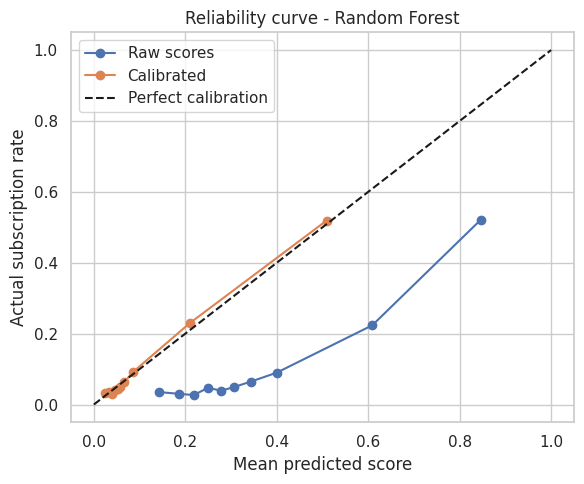

,Version,Brier score,Mean predicted,ROC-AUC,Capture top 20%
0,Raw scores,0.142,0.358,0.813,0.661
1,Calibrated,0.075,0.112,0.813,0.662


In [102]:
# Raw and calibrated test-set probabilities
raw_model = clone(final_model).fit(X_train, y_train)
p_raw = raw_model.predict_proba(X_test)[:, 1]

cal_model = CalibratedClassifierCV(clone(final_model), method='isotonic', cv=5).fit(X_train, y_train)
p_cal = cal_model.predict_proba(X_test)[:, 1]

# Reliability curve
plt.figure(figsize=(6, 5))
for label, p in [('Raw scores', p_raw), ('Calibrated', p_cal)]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    plt.plot(mean_pred, frac_pos, marker='o', label=label)
plt.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
plt.xlabel('Mean predicted score')
plt.ylabel('Actual subscription rate')
plt.title(f'Reliability curve - {final_name}')
plt.legend()
plt.tight_layout()
plt.show()

# Brier scores and ranking quality
pd.DataFrame({'Version': ['Raw scores', 'Calibrated'],
              'Brier score': [brier_score_loss(y_test, p_raw), brier_score_loss(y_test, p_cal)],
              'Mean predicted': [p_raw.mean(), p_cal.mean()],
              'ROC-AUC': [roc_auc_score(y_test, p_raw), roc_auc_score(y_test, p_cal)],
              'Capture top 20%': [capture_at(y_test, p_raw, 0.2), capture_at(y_test, p_cal, 0.2)]}).round(3)

# **Step 18: Marketing Profile Analysis**

### 18.1 Permutation Importance

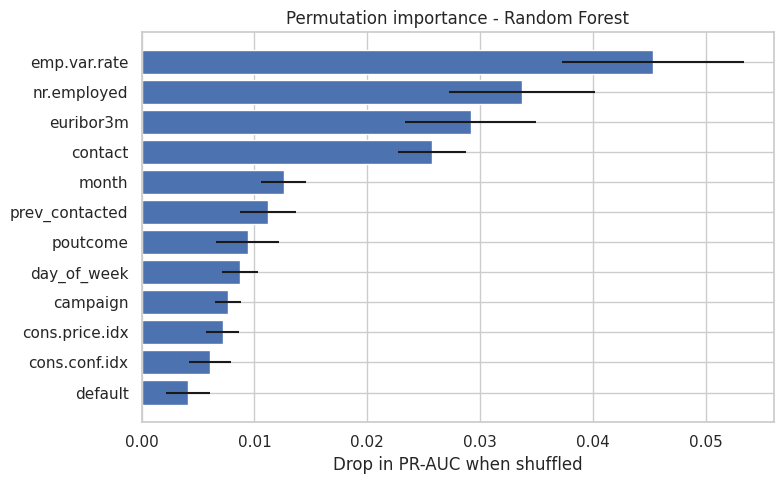

,Feature,Importance,Std
16,emp.var.rate,0.0453,0.0081
20,nr.employed,0.0337,0.0064
19,euribor3m,0.0292,0.0058
6,contact,0.0257,0.0031
7,month,0.0126,0.0020
14,prev_contacted,0.0112,0.0025
9,poutcome,0.0094,0.0028
8,day_of_week,0.0087,0.0016
12,campaign,0.0077,0.0012
17,cons.price.idx,0.0072,0.0014


In [103]:
# Drop in PR-AUC when each feature is shuffled
perm = permutation_importance(raw_model, X_test, y_test, scoring='average_precision',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.DataFrame({'Feature': X_test.columns,
                           'Importance': perm.importances_mean,
                           'Std': perm.importances_std}).sort_values('Importance', ascending=False)

# Plot the 12 most important features
top12 = importance.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top12['Feature'], top12['Importance'], xerr=top12['Std'], color='#4C72B0')
plt.xlabel('Drop in PR-AUC when shuffled')
plt.title(f'Permutation importance - {final_name}')
plt.tight_layout()
plt.show()

importance.head(12).round(4)

### 18.2 Logistic Regression Odds Ratios

In [104]:
# Interpretable companion model: odds ratios (above 1 raises the odds of subscribing)
lr_explain = clone(best_models['Logistic Regression']).fit(X_train, y_train)
feature_names = lr_explain.named_steps['prep'].get_feature_names_out()
odds = pd.DataFrame({'Feature': [n.split('__', 1)[1] for n in feature_names],
                     'Odds ratio': np.exp(lr_explain.named_steps['clf'].coef_[0])})
odds = odds.sort_values('Odds ratio', ascending=False)

display(odds.head(10).round(2))
display(odds.tail(10).round(2))

,Feature,Odds ratio
40,month_mar,3.60
65,cons.price.idx,3.02
37,month_dec,1.56
36,month_aug,1.56
67,euribor3m,1.53
57,age_band_65+,1.45
68,nr.employed,1.45
33,contact_cellular,1.39
23,education_infrequent_sklearn,1.38
62,prev_contacted,1.36


,Feature,Odds ratio
12,marital_divorced,0.86
10,job_unemployed,0.82
54,age_band_35-44,0.81
35,month_apr,0.81
50,poutcome_failure,0.80
34,contact_telephone,0.72
42,month_nov,0.57
41,month_may,0.53
39,month_jun,0.46
64,emp.var.rate,0.11


### 18.3 Profile of the Top 20% Scored Clients

In [105]:
# Flag the 20% of test clients with the highest scores
Xp = X_test.reset_index(drop=True).copy()
Xp['y'] = y_test.reset_index(drop=True)
k = int(np.ceil(0.2 * len(Xp)))
Xp['top20'] = False
Xp.loc[np.argsort(-p_raw)[:k], 'top20'] = True

# Compare each category's share in the top 20% with its share overall
profile_rows = []
for col in ['job', 'education', 'marital', 'age_band', 'contact', 'poutcome',
            'housing', 'loan', 'month', 'day_of_week', 'default']:
    for level, g in Xp.groupby(col):
        if len(g) >= 100:
            profile_rows.append({'Feature': col, 'Level': level,
                                 'Share of all clients': len(g) / len(Xp),
                                 'Share of top 20%': g['top20'].sum() / k,
                                 'Over-representation': (g['top20'].sum() / k) / (len(g) / len(Xp)),
                                 'Yes rate': g['y'].mean()})
profile = pd.DataFrame(profile_rows).sort_values('Over-representation', ascending=False)

display(profile.head(12).round(3))
display(profile.tail(6).round(3))

# Typical values of key numeric features
Xp.groupby('top20')[['age', 'campaign', 'euribor3m', 'prev_contacted']].mean().round(2)

,Feature,Level,Share of all clients,Share of top 20%,Over-representation,Yes rate
31,poutcome,success,0.034,0.169,4.998,0.616
25,age_band,65+,0.015,0.073,4.998,0.517
45,month,oct,0.017,0.083,4.998,0.456
42,month,mar,0.014,0.069,4.998,0.535
46,month,sep,0.013,0.066,4.952,0.486
8,job,student,0.022,0.075,3.341,0.283
38,month,apr,0.066,0.219,3.298,0.208
26,age_band,<25,0.026,0.068,2.616,0.234
5,job,retired,0.040,0.098,2.438,0.230
29,poutcome,failure,0.102,0.180,1.773,0.152


,Feature,Level,Share of all clients,Share of top 20%,Over-representation,Yes rate
43,month,may,0.334,0.175,0.526,0.066
13,education,basic.9y,0.147,0.072,0.486,0.084
1,job,blue-collar,0.220,0.079,0.361,0.067
28,contact,telephone,0.369,0.121,0.327,0.054
40,month,jul,0.172,0.055,0.321,0.083
53,default,unknown,0.211,0.020,0.095,0.045


,age,campaign,euribor3m,prev_contacted
top20,,,,
False,39.94,2.77,4.26,0.00
True,40.50,1.88,1.15,0.19


# **Step 19: Fairness and Responsible-Use Check**

### 19.1 Group Comparison by Age and Marital Status

In [106]:
# Test clients with scores, decisions and the top-20% flag
Xf = X_test.reset_index(drop=True).copy()
Xf['y'] = y_test.reset_index(drop=True).values
Xf['score'] = p_raw
Xf['flag'] = (Xf['score'] >= best_threshold).astype(int)
k = int(np.ceil(0.2 * len(Xf)))
Xf['top20'] = 0
Xf.loc[np.argsort(-p_raw)[:k], 'top20'] = 1

# Group-level report
def group_report(col):
    rows = []
    for level, g in Xf.groupby(col):
        rows.append({'Group': level, 'Clients': len(g), 'Yes rate': g['y'].mean(),
                     'Flagged': g['flag'].mean(),
                     'Precision': precision_score(g['y'], g['flag'], zero_division=0),
                     'Recall': recall_score(g['y'], g['flag'], zero_division=0),
                     'In top 20%': g['top20'].mean()})
    return pd.DataFrame(rows).round(3)

display(group_report('age_band'))
display(group_report('marital'))

,Group,Clients,Yes rate,Flagged,Precision,Recall,In top 20%
0,25-34,2720,0.127,0.166,0.452,0.590,0.236
1,35-44,2734,0.092,0.087,0.550,0.520,0.125
2,45-54,1727,0.075,0.097,0.429,0.558,0.142
3,55-64,721,0.123,0.207,0.376,0.629,0.261
4,65+,120,0.517,0.975,0.521,0.984,1.000
5,<25,214,0.234,0.416,0.438,0.780,0.523


,Group,Clients,Yes rate,Flagged,Precision,Recall,In top 20%
0,divorced,911,0.114,0.111,0.535,0.519,0.168
1,married,5006,0.098,0.124,0.453,0.570,0.166
2,single,2307,0.143,0.212,0.465,0.691,0.287
3,unknown,12,0.083,0.083,0.000,0.000,0.083


### 19.2 Group Comparison by Job

In [107]:
# Job groups, largest first
group_report('job').sort_values('Clients', ascending=False)

,Group,Clients,Yes rate,Flagged,Precision,Recall,In top 20%
0,admin.,2150,0.132,0.194,0.472,0.696,0.257
1,blue-collar,1813,0.067,0.035,0.500,0.262,0.072
9,technician,1319,0.112,0.133,0.474,0.561,0.177
7,services,786,0.081,0.073,0.421,0.375,0.121
4,management,584,0.110,0.142,0.458,0.594,0.199
5,retired,330,0.230,0.458,0.444,0.882,0.488
6,self-employed,307,0.111,0.173,0.396,0.618,0.238
2,entrepreneur,297,0.081,0.088,0.385,0.417,0.152
10,unemployed,202,0.198,0.262,0.566,0.750,0.337
3,housemaid,201,0.085,0.139,0.536,0.882,0.184


# **Step 20: Recommendation, Limitations and Responsible Use**

### 20.1 Recommendation, Limitations and Responsible Use


## Recommendation for the bank
1. **Use the model to rank clients, not to decide automatically.** The final model is a tuned Random Forest
   (selected over XGBoost because the two tied in cross-validation, p = 0.85, and Random Forest held up better in
   the later period). Contacting the top 20% of scored clients found about 66% of subscribers in the held-out test
   set, against about 20% by random calling.
2. **Choose the contact list by capacity (top N%), not by a fixed score cutoff.** Under the time shift, a fixed
   threshold found far fewer subscribers (recall 0.607 in the random test, 0.372 in the later period).
3. **Decide how many to call using real economics.** With illustrative value-to-cost ratios of 5:1 and 10:1, calling
   only the top 20% beats calling everyone; at 20:1 the best cutoff widens to 40%. The bank should replace these
   assumptions with its actual cost per contact and value per deposit.
4. **Prioritise actionable signals:** clients with a previous campaign success (62% subscribe), mobile-phone contact,
   and avoid repeated contacts. Treat month and economic variables as context, not customer traits.
5. **Keep Logistic Regression as an explanation companion.** It is within about 1 point of the top 20% capture of the
   best model (62.6% vs 63.6%-63.9% in cross-validation), is easy to explain, and was the second most robust model
   over time.
6. **Refresh and monitor.** Retrain and recalibrate each campaign; track precision, recall and group-level
   selection rates.

## Limitations
- **Time dependence.** The subscription rate rose from 6.4% to 30.8% between early and later periods; on a later-period
  test, ROC-AUC fell from 0.81 to 0.73 and top-20% capture from 66% to 39%. Headline numbers are optimistic for the future.
- **Context-driven performance.** Much of the signal comes from economic indicators, channel and timing (Step 15, 18).
- **`duration` was excluded** because it is unknown before the call; using it would inflate ROC-AUC from 0.80 to 0.94.
- **No client ID.** Repeat contacts of the same client cannot be linked, so train and test may share clients.
- **Single dataset and country** (a Portuguese bank, 2008-2010, a financial-crisis period).
- **Tuning and selection used the same training data**, without nested cross-validation, which can be slightly optimistic.
- **Business values are assumed.** Cost-benefit figures use illustrative ratios.
- **Associations, not causes.** Profile findings describe patterns in historical data.

## Responsible-AI considerations
- The model uses age and marital status. Group results (Step 19) show very high targeting of clients aged 65+ and
  low recall for some job groups. Use suitability and consent checks, human review, and monitoring.
- Do not use the score to deny service or to pressure customers; it only orders a contact list.
- Data minimisation and privacy: use only the fields needed, and follow the bank's data-protection rules.
- Probabilities from the class-weighted model are inflated; use the calibrated version for any expected-value use.

### 20.2 Reproducibility: Software Versions, Dataset Fingerprint and Saved Results

In [108]:
# Software versions
import sys, sklearn, xgboost, imblearn, scipy
print('Python:', sys.version.split()[0])
for lib in [np, pd, sklearn, xgboost, imblearn, scipy]:
    print(f'{lib.__name__}: {lib.__version__}')

# Dataset fingerprint check
EXPECTED_SHA256 = '74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8'
print('Dataset SHA-256 matches:', sha256_of(DATA_FILE) == EXPECTED_SHA256)
print('Random seed:', RANDOM_STATE)

# Save key results
os.makedirs('outputs', exist_ok=True)
test_results.to_csv('outputs/test_results.csv', index=False)
comparison_table.to_csv('outputs/cv_comparison.csv')
lift_table.to_csv('outputs/lift_table.csv')
ablation_results.to_csv('outputs/ablation_results.csv', index=False)
time_results.to_csv('outputs/time_split_results.csv', index=False)
print('Results saved to the outputs folder.')

Python: 3.13.16
numpy: 2.1.3
pandas: 2.2.3
sklearn: 1.6.1
xgboost: 3.4.1
imblearn: 0.14.2
scipy: 1.16.3
Dataset SHA-256 matches: True
Random seed: 42
Results saved to the outputs folder.


### 20.3 AI-Use Declaration

**AI-use declaration:** We used an AI assistant (Claude, by Anthropic) during this project for: (1) advice on notebook
structure and validation design, (2) explaining methods and metrics, and (3) drafting and debugging code. We ran all
code ourselves, checked the outputs against the dataset, and wrote the decision logs and interpretations after
reviewing the results. AI-generated code and explanations were edited and verified by the group; final decisions
and responsibility are ours.

## Decision Log

### A. Data and preprocessing decisions

| # | Decision (options considered) | Choice and reason | Evidence |
|---|---|---|---|
| 1 | Dataset version (bank-full / bank-additional-full) | bank-additional-full: more inputs, 5 economic indicators, date order allows a time-based check | 41,188 x 21; SHA-256 74adfc57...afb4d8 |
| 2 | Duplicates (keep / remove) | Remove, keep first: avoids train/test leakage | 12 duplicates |
| 3 | "unknown" values (drop rows / drop columns / impute / keep as category) | Keep as category: dropping loses rows, imputing invents data | default 20.87% unknown |
| 4 | pdays = 999 (leave / convert) | Flag plus cleaned value: 999 is a code, not a number of days | 96.3% are 999 |
| 5 | Rare categories (drop / merge / group) | Group as "infrequent" (<30 rows): too rare to learn reliably | default = yes: 3 rows |
| 6 | Main split (random / time-based) | Random stratified 80/20 as main, time-based as sensitivity check: random fits the ranking question, time shows deployment risk | Yes rate 6.4% vs 30.8% |
| 7 | `duration` (keep / drop / benchmark only) | Drop, use only in an ablation: unknown before contact | ROC-AUC 0.798 to 0.941 with it |
| 8 | Economic indicators (keep / drop) | Keep, then ablate: collinear but informative | Correlation 0.91-0.97; ROC-AUC 0.798 to 0.775 without |
| 9 | age (numeric / bands / both) | Both: response is U-shaped | 24.0% / 8.6% / 47.3% |
| 10 | Feature engineering (none / flags and bands) | prev_contacted, pdays_clean, age_band: handle codes and non-linearity | See preprocessing and feature log |
| 11 | Split (random 80/20 stratified) | random_state = 42: same yes rate in both parts | Train 32,940 / Test 8,236, both 0.1127 |
| 12 | Leakage control (trust / assertions) | Assertions in code: automatic and visible | "Leakage checks passed." |
| 13 | Encoding (label / one-hot / target) | One-hot: no natural order, target encoding risks leakage | 21 features to 69 columns |
| 14 | Scaling and skew (none / standardise / log) | Log for skewed counts, standardise numerics: long right tails | campaign skew |
| 15 | Where to fit preprocessing (whole data / train only / in Pipeline) | In Pipeline, per fold: no leakage | Train means 0, test not 0 |

### B. Modelling, evaluation and interpretation decisions

| # | Decision (options considered) | Choice and reason | Evidence |
|---|---|---|---|
| 16 | Validation method (hold-out / k-fold / repeated) | Stratified 5-fold on train, test used once: stable and no peeking | LR PR-AUC 0.445 +/- 0.013 |
| 17 | Primary metrics (accuracy / F1 / ROC-AUC / PR-AUC) | PR-AUC and ROC-AUC, plus precision, recall, F1: imbalanced data, ranking use | Dummy accuracy 0.887, recall 0 |
| 18 | Imbalance handling (none / class weights / SMOTE) | Class weights: same ranking quality as SMOTE, simpler | PR-AUC LR 0.445 vs SMOTE 0.441 |
| 19 | Models (baseline only / several) | Dummy, Logistic Regression, Decision Tree, Random Forest, XGBoost: simple to powerful | 5 models |
| 20 | Tuning (defaults / grid / random search) | Grid (LR, Tree), random (RF, XGB), 3-fold, PR-AUC: fair at moderate cost | Best CV PR-AUC: RF 0.464, XGB 0.463, LR 0.444, DT 0.428 |
| 21 | Comparison design (single split / repeated CV) | 5x2 CV plus corrected paired t-test: folds share training data | XGB vs RF p = 0.85; XGB vs LR p = 0.005 |
| 22 | Initial model choice (XGB / RF / LR) | XGBoost (superseded by #28): best ROC-AUC, recall and capture in CV | PR-AUC 0.465 vs 0.465 (tie) |
| 23 | Threshold (0.5 / F1-max / capacity) | F1-max 0.632 on out-of-fold training scores: 0.5 is arbitrary with class weights | F1 0.501; flat from 0.55 to 0.75 |
| 24 | Test-set use (tune on test / evaluate once) | Evaluate once, with bootstrap intervals: test stands in for future data | RF PR-AUC CI 0.451-0.521 |
| 25 | Business evaluation (metrics only / lift and cost) | Decile lift, gain curves, assumed cost-benefit: links to the stakeholder decision | Top 20% captures 66.1%; decile 1 lift 4.6 |
| 26 | Feature ablation (none / feature groups) | Feature sets A-E with out-of-fold scores: quantifies leakage and reliance on context | duration 0.798 to 0.941; economic 0.798 to 0.775 |
| 27 | Time validation (random only / add time split) | Add as sensitivity check: closest to deployment | ROC-AUC 0.81 falls to 0.56-0.73 |
| 28 | Final model, revises #22 (XGB / RF / LR) | Random Forest: tied with XGB in CV, more robust under time shift | Time split ROC-AUC RF 0.729 vs XGB 0.669 |
| 29 | Calibration (raw / sigmoid / isotonic) | Isotonic for any expected-value use, raw scores for ranking: class weights inflate scores | Brier 0.142 to 0.075 |
| 30 | Interpretation (coefficients / importance / profiling) | Permutation importance, LR odds ratios, top-20% profile: complementary views | emp.var.rate, nr.employed, euribor3m, contact lead |
| 31 | Fairness check (none / group report) | Group report by age, marital status and job: sensitive attributes are in the model | 65+: 97.5% flagged; blue-collar recall 0.262 vs retired 0.882 |